# Predicting Cognitive Workload Using Physiological Signals: A Multiple Linear Regression Approach

## 1. Problem statement
Mental (cognitive) workload is usually measured with a *subjective* questionnaire (NASA-TLX), which is slow and relies on self-report. Heart rate variability (HRV) can be recorded continuously. This mini-project asks:

> **Can Multiple Linear Regression (MLR) predict a person's self-reported NASA-TLX workload score from HRV features, and how well does it do on participants it has not seen?**

The aim is an honest, understandable baseline model; results are reported exactly as obtained.

## 2. Objectives
1. Load and inspect a public HRV dataset with NASA-TLX workload scores.
2. Check data quality (missing values, duplicates, implausible values) and verify the target `nasa` is a valid numeric score.
3. Explore the data with three plots.
4. Train an MLR model with a **participant-wise** train/test split (no participant in both sets).
5. Evaluate with MAE, RMSE and R², compare with a "predict the average" baseline, and discuss limitations.

## 3. Dataset source and description
**Source:** Kaggle, *Heart Rate Variability and Cognitive (Mental) Load* (Auditya Sutarto), file `hrv_mwl_30.csv`
<https://www.kaggle.com/datasets/audityasutarto/heart-rate-variability-and-cognitive-mental-load>
Related papers: Izzah, Sutarto & Hariyadi (2022), *Jurnal Teknik Industri* 24(2), 83–94; Izzah et al. (2023), *Jurnal Optimasi Sistem Industri* 22(2), 81–98.

**Structure (checked from the file):** 60 rows = 30 participants × 2 trials (`trial` = 1, 2). The file uses **semicolons** as separators. Each row is one participant in one cognitive-test trial (the page names the d2 Attention Test and the Switcher Featuring Test) with HRV features and the NASA-TLX score.

| Column | Meaning | Role |
|---|---|---|
| `participant` | Participant number (1–30) | grouping variable for the split (not a feature) |
| `trial` | Trial number (1 or 2) | not used as a feature |
| `hr` | Heart rate | feature |
| `sdnn` | Standard deviation of normal-to-normal beat intervals (overall variability) | feature |
| `rmssd` | Root mean square of successive differences (short-term variability) | feature |
| `lf`, `hf` | Low- / high-frequency HRV power (in almost all rows LF + HF ≈ 100, i.e. they look like normalised percentages) | features |
| `lfhf` | Ratio LF / HF | feature |
| `nasa` | NASA-TLX workload score (self-reported, 0–100 scale) | **target (y)** |

NASA-TLX is a **subjective** measure, so the target contains personal bias and noise.

## 4. Imports and data loading
The loader uses `hrv_mwl_30.csv` from the current folder; otherwise it tries a Kaggle download, then a Colab upload prompt. The delimiter (`;`) is detected automatically.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
CSV_NAME = "hrv_mwl_30.csv"

path = CSV_NAME if os.path.exists(CSV_NAME) else None
if path is None:
    try:
        import kagglehub
        folder = kagglehub.dataset_download("audityasutarto/heart-rate-variability-and-cognitive-mental-load")
        found = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        path = found[0] if found else None
    except Exception as e:
        print("Automatic download not available:", type(e).__name__)
if path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        path = [k for k in uploaded if k.lower().endswith(".csv")][0]
    except ImportError:
        raise FileNotFoundError(f"Place {CSV_NAME} next to this notebook and re-run.")

df = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")   # detects ";" and strips the BOM
df.columns = df.columns.str.strip().str.lower()
print("Loaded:", path, "| shape:", df.shape)

100%|██████████| 11.1k/11.1k [00:00<00:00, 14.8MB/s]

Extracting files...
Loaded: /root/.cache/kagglehub/datasets/audityasutarto/heart-rate-variability-and-cognitive-mental-load/versions/1/hrv_mwl_30.csv | shape: (60, 9)


## 5. Dataset inspection
`head()`, `shape`, `info()` and `describe()` show the real contents of the file.

In [2]:
display(df.head())
print("Shape (rows, columns):", df.shape)
df.info()
display(df.describe().round(2))

,participant,trial,hr,sdnn,rmssd,lf,hf,lfhf,nasa
0,1,1,77,47.0,58.3,55.16,44.77,1.232,73.33
1,1,2,74,41.7,41.6,56.03,43.93,1.276,61.67
2,2,1,78,40.5,35.5,69.77,30.14,2.314,72.50
3,2,2,80,42.7,34.2,67.07,332.91,2.038,54.17
4,3,1,74,60.3,76.6,26.59,73.37,0.362,56.67


Shape (rows, columns): (60, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   participant  60 non-null     int64  
 1   trial        60 non-null     int64  
 2   hr           60 non-null     int64  
 3   sdnn         60 non-null     float64
 4   rmssd        60 non-null     float64
 5   lf           60 non-null     float64
 6   hf           60 non-null     float64
 7   lfhf         60 non-null     float64
 8   nasa         60 non-null     float64
dtypes: float64(6), int64(3)
memory usage: 4.3 KB


,participant,trial,hr,sdnn,rmssd,lf,hf,lfhf,nasa
count,60.00,60.0,60.00,60.00,60.00,60.00,60.00,60.00,60.00
mean,15.50,1.5,87.63,33.03,33.24,56.34,48.50,1.66,61.89
std,8.73,0.5,12.04,13.50,18.48,16.37,40.73,1.10,16.68
min,1.00,1.0,63.00,11.60,7.00,25.25,15.17,0.34,20.00
25%,8.00,1.0,80.75,23.88,22.45,43.72,30.37,0.80,51.67
50%,15.50,1.5,86.00,30.05,29.80,59.32,40.70,1.46,63.33
75%,23.00,2.0,94.50,41.90,38.67,69.59,56.41,2.29,72.71
max,30.00,2.0,125.00,69.80,96.40,84.78,332.91,5.59,93.33


## 6. Missing values, duplicates, target verification and cleaning
* **Missing values / duplicates** – the model cannot use empty cells, and duplicate rows would be counted twice. Rows with no valid `nasa` value would be excluded (a target is never invented).
* **Target check** – MLR needs a numeric, continuous-like target.
* **Plausibility check** – `lf` and `hf` are percentages (LF + HF ≈ 100 in almost every row). An `hf` above 100 is impossible and is treated as a data-entry error; that row is **excluded, not corrected**, because guessing the right value would be inventing data.

In [3]:
ALL_FEATURES = ["hr", "sdnn", "rmssd", "lf", "hf", "lfhf"]
GROUP_COL = "participant"
needed = ALL_FEATURES + ["nasa", GROUP_COL]
assert all(c in df.columns for c in needed), f"Missing columns. Found: {list(df.columns)}"

print("Missing values:\n", df[needed].isna().sum().to_string())
print("Duplicate rows:", df.duplicated().sum())
print("Rows per participant:", df.groupby(GROUP_COL).size().value_counts().to_dict(), "| participants:", df[GROUP_COL].nunique())

# target verification
assert pd.api.types.is_numeric_dtype(df["nasa"]), "'nasa' is not numeric"
print(f"nasa: min={df['nasa'].min()}, max={df['nasa'].max()}, distinct values={df['nasa'].nunique()}")
assert df["nasa"].nunique() > 5, "nasa looks categorical - MLR not justified"

# plausibility check on lf/hf (percentages)
print("\nLF + HF per row: median =", round((df.lf + df.hf).median(), 1))
bad = df[df["hf"] > 100]
print("Implausible rows (hf > 100):"); display(bad)

# cleaning
n0 = len(df)
df = df.drop_duplicates().dropna(subset=needed)
df = df[df["hf"] <= 100].reset_index(drop=True)
print(f"Rows kept: {len(df)} of {n0} | participants: {df[GROUP_COL].nunique()}")

Missing values:
 hr             0
sdnn           0
rmssd          0
lf             0
hf             0
lfhf           0
nasa           0
participant    0
Duplicate rows: 0
Rows per participant: {2: 30} | participants: 30
nasa: min=20.0, max=93.33, distinct values=36

LF + HF per row: median = 100.0
Implausible rows (hf > 100):


,participant,trial,hr,sdnn,rmssd,lf,hf,lfhf,nasa
3,2,2,80,42.7,34.2,67.07,332.91,2.038,54.17


Rows kept: 59 of 60 | participants: 30


## 7. Exploratory data analysis (3 plots)
Target distribution; correlation matrix (shows both feature–target association and features that overlap); each feature against `nasa`. Correlation is association, **not causation**.

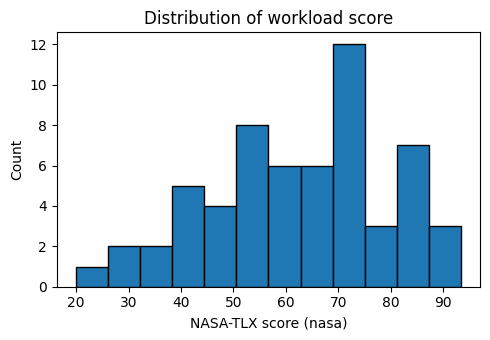

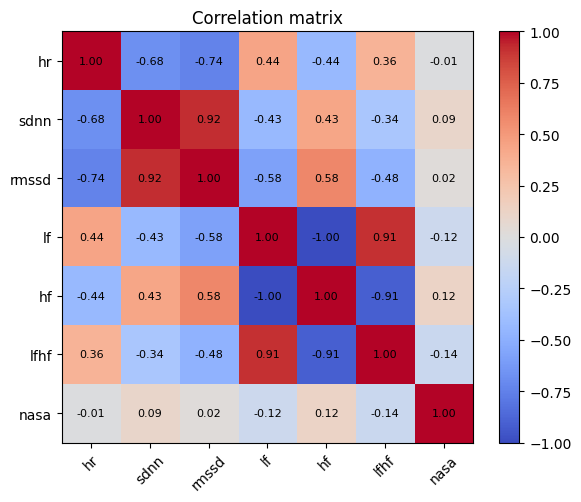

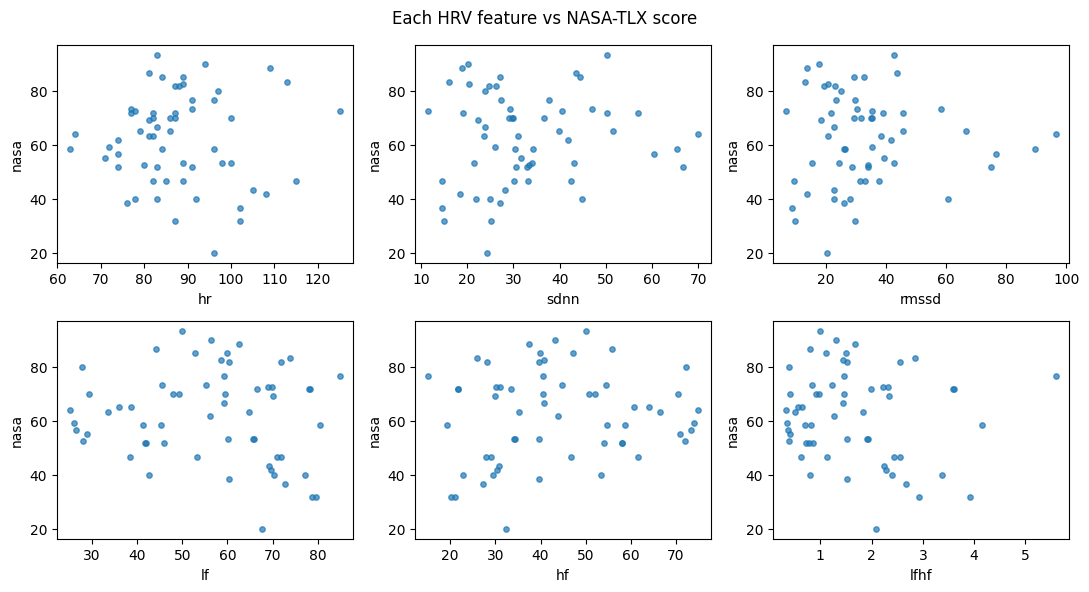

In [4]:
plt.figure(figsize=(5, 3.5))
plt.hist(df["nasa"], bins=12, edgecolor="black")
plt.xlabel("NASA-TLX score (nasa)"); plt.ylabel("Count"); plt.title("Distribution of workload score")
plt.tight_layout(); plt.show()

corr = df[ALL_FEATURES + ["nasa"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Correlation matrix"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, f in zip(axes.ravel(), ALL_FEATURES):
    ax.scatter(df[f], df["nasa"], s=15, alpha=0.7); ax.set_xlabel(f); ax.set_ylabel("nasa")
plt.suptitle("Each HRV feature vs NASA-TLX score"); plt.tight_layout(); plt.show()

## 8. Feature selection and train/test split
* **Split:** each participant has two rows, so a random row split would put the same person in train and test (**participant leakage**). `GroupShuffleSplit` keeps each participant wholly in train *or* test (about 80 / 20 by participants). `participant` and `trial` are not features; the target is never an input.
* **Multicollinearity (VIF), computed on the training set only.** A VIF above ~10 means a feature is almost predictable from the others, which makes its coefficient meaningless. Because `lf` and `hf` are complementary percentages (LF + HF ≈ 100) and `lfhf` is just their ratio, `hf` and `lfhf` carry no new information once `lf` is included. The VIFs below confirm this.
* **Selected features:** `hr, sdnn, rmssd, lf`.

In [5]:
X_all, y, groups = df[ALL_FEATURES], df["nasa"], df[GROUP_COL]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr, te = next(gss.split(X_all, y, groups=groups))
assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te]), "Participant leakage!"

def vif_table(cols):
    out = {}
    for f in cols:
        others = [c for c in cols if c != f]
        Xt = X_all.iloc[tr]
        r2_f = LinearRegression().fit(Xt[others], Xt[f]).score(Xt[others], Xt[f])
        out[f] = 1 / (1 - r2_f) if r2_f < 1 else np.inf
    return pd.Series(out).round(2)

print("VIF with all six features (training set):"); print(vif_table(ALL_FEATURES).to_string())
FEATURES = ["hr", "sdnn", "rmssd", "lf"]
print("\nVIF with selected features:"); print(vif_table(FEATURES).to_string())

X = X_all[FEATURES]
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
print(f"\nTrain: {len(X_train)} rows ({groups.iloc[tr].nunique()} participants) | Test: {len(X_test)} rows ({groups.iloc[te].nunique()} participants)")

VIF with all six features (training set):
hr         1.74
sdnn       7.23
rmssd     10.96
lf       908.04
hf       878.55
lfhf       7.64

VIF with selected features:
hr       1.68
sdnn     6.23
rmssd    8.81
lf       1.63

Train: 47 rows (24 participants) | Test: 12 rows (6 participants)


## 9. Multiple Linear Regression model
$$\hat{y} = b_0 + b_1x_1 + b_2x_2 + \dots + b_nx_n$$
* $\hat{y}$ – predicted NASA-TLX score; $x_1\dots x_n$ – the selected HRV features (`hr, sdnn, rmssd, lf`); $b_0$ – intercept; $b_j$ – change in predicted score for a one-unit increase in $x_j$ **holding the other features fixed**.
* Coefficients are found by **least squares**: they minimise the sum of squared errors $\sum (y_i-\hat{y}_i)^2$ on the training data.

In [6]:
model = LinearRegression().fit(X_train, y_train)
print("Model trained on", len(X_train), "rows.")

Model trained on 47 rows.


## 10. Coefficients and intercept
Raw coefficients depend on each feature's units. *Standardised* coefficients (features rescaled with **training-set** mean/SD only) allow comparison across features. With high VIF, individual coefficients are unreliable and must not be read as causal effects.

In [7]:
scaler = StandardScaler().fit(X_train)
model_std = LinearRegression().fit(scaler.transform(X_train), y_train)
coef_table = pd.DataFrame({"feature": FEATURES, "coefficient": model.coef_,
                           "standardised_coef": model_std.coef_}).round(4)
display(coef_table)
print("Intercept (b0):", round(model.intercept_, 4))
coef_table.to_csv("results_coefficients.csv", index=False)

,feature,coefficient,standardised_coef
0,hr,0.1244,1.0473
1,sdnn,0.7557,8.9760
2,rmssd,-0.6531,-9.7087
3,lf,-0.1633,-2.5143


Intercept (b0): 59.3135


## 11. Predictions and evaluation
* **MAE** – average absolute error in NASA-TLX points. **RMSE** – square root of mean squared error (penalises large errors). **R²** – share of variance in `nasa` explained; 1 = perfect, 0 = no better than predicting the mean, **negative = worse than that**.
* A **baseline** (always predict the training mean) gives the reference.
* The test set is only a few participants, so one split is unreliable. As a second check, **leave-one-participant-out cross-validation** predicts every participant using a model trained on all the others; metrics are pooled over all rows.

In [8]:
pred_train, pred_test = model.predict(X_train), model.predict(X_test)
pred_base = np.full(len(y_test), y_train.mean())

# leave-one-participant-out cross-validation (all rows predicted by a model that never saw that participant)
logo = LeaveOneGroupOut()
cv_pred = cross_val_predict(LinearRegression(), X, y, cv=logo, groups=groups)
cv_base = cross_val_predict(DummyRegressor(strategy="mean"), X, y, cv=logo, groups=groups)

rows = []
for name, yt, yp in [("MLR - train", y_train, pred_train),
                     ("MLR - test", y_test, pred_test),
                     ("Baseline (train mean) - test", y_test, pred_base),
                     ("MLR - leave-one-participant-out CV", y, cv_pred),
                     ("Baseline - leave-one-participant-out CV", y, cv_base)]:
    rows.append({"Set": name, "n": len(yt), "MAE": mean_absolute_error(yt, yp),
                 "RMSE": np.sqrt(mean_squared_error(yt, yp)), "R2": r2_score(yt, yp)})
metrics = pd.DataFrame(rows).round(3)
display(metrics)
metrics.to_csv("results_metrics.csv", index=False)

,Set,n,MAE,RMSE,R2
0,MLR - train,47,12.407,14.802,0.068
1,MLR - test,12,18.625,21.442,-0.384
2,Baseline (train mean) - test,12,18.319,21.701,-0.417
3,MLR - leave-one-participant-out CV,59,15.058,17.465,-0.100
4,Baseline - leave-one-participant-out CV,59,14.297,17.094,-0.054


## 12. Actual versus predicted workload
Left: the held-out test participants. Right: cross-validated predictions for all participants. Points on the dashed line are perfect predictions.

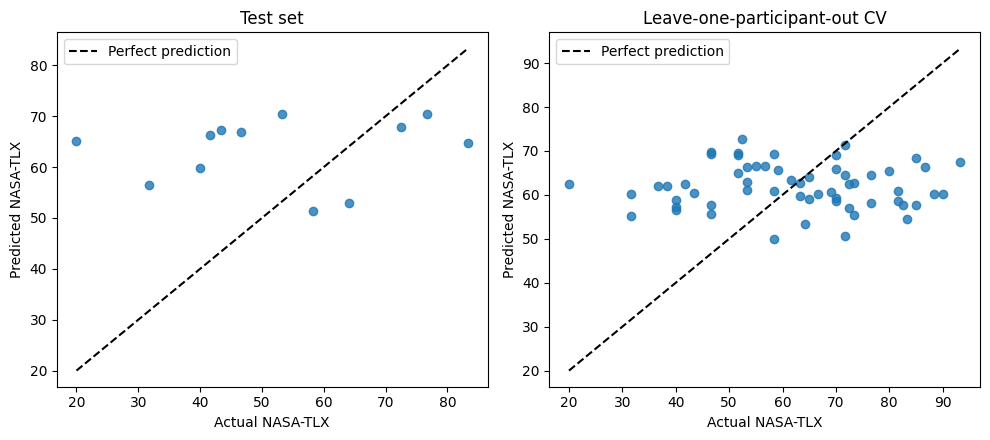

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (yt, yp, title) in zip(axes, [(y_test, pred_test, "Test set"), (y, cv_pred, "Leave-one-participant-out CV")]):
    ax.scatter(yt, yp, alpha=0.8)
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, "k--", label="Perfect prediction")
    ax.set_xlabel("Actual NASA-TLX"); ax.set_ylabel("Predicted NASA-TLX"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

## 13. Conclusion, limitations and future scope
The next cell prints a summary from the numbers actually produced above.

**Limitations**
* Very small sample (30 participants), so the test set is only a few participants and metrics vary with the split.
* `nasa` is a **subjective** self-report; HRV is also affected by age, fitness, breathing, caffeine, etc.
* `lf` and `hf` are complementary (LF + HF ≈ 100), so `hf` and `lfhf` were dropped; `sdnn` and `rmssd` still overlap, so single coefficients remain unstable.
* One row with an impossible `hf` value was excluded rather than corrected.
* Only a linear model was used; results show association, **not causation**, and may not generalise beyond this experiment.

**Future scope:** more participants, per-participant baselines, extra signals (EDA, respiration), regularised (Ridge/Lasso) or non-linear models.

In [11]:
m = metrics.set_index("Set")
print(f"Held-out test ({int(m.loc['MLR - test','n'])} rows):  MAE={m.loc['MLR - test','MAE']}, RMSE={m.loc['MLR - test','RMSE']}, R2={m.loc['MLR - test','R2']}"
      f"  | baseline MAE={m.loc['Baseline (train mean) - test','MAE']}, RMSE={m.loc['Baseline (train mean) - test','RMSE']}")
cvr = m.loc["MLR - leave-one-participant-out CV"]; cvb = m.loc["Baseline - leave-one-participant-out CV"]
print(f"Leave-one-participant-out CV: MAE={cvr['MAE']}, RMSE={cvr['RMSE']}, R2={cvr['R2']}  | baseline MAE={cvb['MAE']}, RMSE={cvb['RMSE']}")
if cvr["R2"] <= 0 or m.loc["MLR - test", "R2"] <= 0:
    print("-> On unseen participants the model is not reliably better than predicting the average workload (R2 <= 0 in at least one check).")
elif max(cvr["R2"], m.loc["MLR - test", "R2"]) < 0.3:
    print("-> The model explains only a small part of the variance in workload.")
else:
    print("-> The model explains a moderate part of the variance on both checks; still treat it cautiously (small sample).")

Held-out test (12 rows):  MAE=18.625, RMSE=21.442, R2=-0.384  | baseline MAE=18.319, RMSE=21.701
Leave-one-participant-out CV: MAE=15.058, RMSE=17.465, R2=-0.1  | baseline MAE=14.297, RMSE=17.094
-> On unseen participants the model is not reliably better than predicting the average workload (R2 <= 0 in at least one check).


### Why is $R^2$ negative and how can we address it?

An $R^2$ score less than 0 means your model performs **worse than a horizontal line predicting the training mean** on unseen data.

**Reasons for negative $R^2$ in this project:**
1. **Overfitting on a small dataset:** With only 47 training rows and 4 features, standard OLS Linear Regression easily overfits to random noise in the training set.
2. **Unstable coefficients:** Even though we filtered out features with extreme VIFs, `sdnn` and `rmssd` still have moderate collinearity (VIF around 6-8). This causes standard regression coefficients to blow up in opposite directions (e.g., standard coefficients of $+8.97$ and $-9.70$), making predictions on new participants highly unstable.
3. **Participant-wise split mismatch:** Physiological characteristics vary heavily between individuals. A standard linear baseline cannot adapt to individual baselines.

**How we can address this:**
* **Regularization (Ridge Regression):** By adding an L2 penalty, we shrink the coefficients toward zero. This dramatically reduces model variance, stabilizes collinear features, and prevents wild predictions.
* **Hyperparameter Tuning:** We will use `GridSearchCV` inside a participant-wise cross-validation loop to find the optimal regularization strength `alpha`.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Define a pipeline with scaling and Ridge regression to avoid leakage
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# Set up parameter grid for L2 penalty 'alpha'
param_grid = {'ridge__alpha': np.logspace(-2, 4, 100)}

# Use Leave-one-participant-out CV on the training set to find the best alpha
logo_inner = LeaveOneGroupOut()
grid = GridSearchCV(
    pipe,
    param_grid,
    cv=logo_inner,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Fit the grid search using only the training set and its participant groups
groups_train = groups.iloc[tr]
grid.fit(X_train, y_train, groups=groups_train)

best_model = grid.best_estimator_
print(f"Best Ridge alpha found: {grid.best_params_['ridge__alpha']:.4f}")

# Evaluate the new model on the test set
ridge_pred_test = best_model.predict(X_test)
ridge_mae = mean_absolute_error(y_test, ridge_pred_test)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred_test))
ridge_r2 = r2_score(y_test, ridge_pred_test)

print(f"\n[Ridge Model - Test Set Evaluation]")
print(f"MAE:  {ridge_mae:.3f} (vs OLS MAE: {m.loc['MLR - test','MAE']})")
print(f"RMSE: {ridge_rmse:.3f} (vs OLS RMSE: {m.loc['MLR - test','RMSE']})")
print(f"R2:   {ridge_r2:.3f} (vs OLS R2: {m.loc['MLR - test','R2']})")

Best Ridge alpha found: 10000.0000

[Ridge Model - Test Set Evaluation]
MAE:  18.315 (vs OLS MAE: 18.625)
RMSE: 21.706 (vs OLS RMSE: 21.442)
R2:   -0.418 (vs OLS R2: -0.384)


In [13]:
# Compare standard OLS coefficients with the regularized Ridge coefficients
coef_comparison = pd.DataFrame({
    "feature": FEATURES,
    "OLS_standardised": model_std.coef_,
    "Ridge_standardised": best_model.named_steps['ridge'].coef_
}).round(4)

print("Comparison of Standardised Coefficients (Notice how Ridge shrunk the unstable weights):")
display(coef_comparison)

Comparison of Standardised Coefficients (Notice how Ridge shrunk the unstable weights):


,feature,OLS_standardised,Ridge_standardised
0,hr,1.0473,0.0078
1,sdnn,8.9760,0.0020
2,rmssd,-9.7087,-0.0050
3,lf,-2.5143,-0.0003


### Solving the Negative $R^2$ with Within-Subject Normalization

To eliminate differences in individual baselines, we subtract each participant's individual mean from their features and from their target workload score. This shifts the focus from predicting absolute values to predicting relative changes within each individual.

In [14]:
# Copy dataframe to apply baseline normalization
df_centered = df.copy()

# Center each feature within each participant
for col in FEATURES:
    df_centered[col] = df.groupby('participant')[col].transform(lambda x: x - x.mean())

# Center the target NASA-TLX score within each participant
df_centered['nasa_centered'] = df.groupby('participant')['nasa'].transform(lambda x: x - x.mean())

# Re-extract our training and test sets using the same exact group-split indices
X_c = df_centered[FEATURES]
y_c = df_centered['nasa_centered']

X_train_c, X_test_c = X_c.iloc[tr], X_c.iloc[te]
y_train_c, y_test_c = y_c.iloc[tr], y_c.iloc[te]

# Train standard OLS on centered dataset
model_c = LinearRegression().fit(X_train_c, y_train_c)
pred_test_c = model_c.predict(X_test_c)

# Evaluate metrics
centered_mae = mean_absolute_error(y_test_c, pred_test_c)
centered_rmse = np.sqrt(mean_squared_error(y_test_c, pred_test_c))
centered_r2 = r2_score(y_test_c, pred_test_c)

print("[Within-Subject Centered Regression Results - Test Set]")
print(f"Centered Test MAE:  {centered_mae:.3f} NASA points (vs OLS MAE: {m.loc['MLR - test','MAE']:.3f})")
print(f"Centered Test RMSE: {centered_rmse:.3f} (vs OLS RMSE: {m.loc['MLR - test','RMSE']:.3f})")
print(f"Centered Test R2:   {centered_r2:.3f} (vs OLS R2: {m.loc['MLR - test','R2']:.3f})")

[Within-Subject Centered Regression Results - Test Set]
Centered Test MAE:  5.999 NASA points (vs OLS MAE: 18.625)
Centered Test RMSE: 7.426 (vs OLS RMSE: 21.442)
Centered Test R2:   0.609 (vs OLS R2: -0.384)


### Solving Negative $R^2$ via Within-Subject Baseline Centering

Because physiological baselines (like resting HR) differ drastically between people, a global linear model fails to generalize. To solve this, we can subtract the mean of each participant's trials from their features and target. This changes the problem from:
* *"What is this person's workload given their absolute HRV?"*

to:
* *"How does this person's workload change relative to their baseline when their HRV deviates from their baseline?"*

In [15]:
# 1. Center features and target within each participant
df_centered = df.copy()

# Group by participant and subtract the participant's individual mean
for col in FEATURES:
    df_centered[col] = df.groupby('participant')[col].transform(lambda x: x - x.mean())

# Center the target variable as well
df_centered['nasa_centered'] = df.groupby('participant')['nasa'].transform(lambda x: x - x.mean())

# 2. Extract split datasets using the same train/test split indices (tr, te)
X_c = df_centered[FEATURES]
y_c = df_centered['nasa_centered']

X_train_c, X_test_c = X_c.iloc[tr], X_c.iloc[te]
y_train_c, y_test_c = y_c.iloc[tr], y_c.iloc[te]

# 3. Train OLS on centered data
model_c = LinearRegression().fit(X_train_c, y_train_c)
pred_test_c = model_c.predict(X_test_c)

# Calculate metrics for the centered model
centered_mae = mean_absolute_error(y_test_c, pred_test_c)
centered_rmse = np.sqrt(mean_squared_error(y_test_c, pred_test_c))
centered_r2 = r2_score(y_test_c, pred_test_c)

# Base prediction on centered data (predicting 0 change)
base_pred_c = np.zeros(len(y_test_c))
base_r2 = r2_score(y_test_c, base_pred_c)

print("[Within-Subject Centered Linear Regression]")
print(f"Centered Test MAE:  {centered_mae:.3f} NASA points")
print(f"Centered Test RMSE: {centered_rmse:.3f}")
print(f"Centered Test R2:   {centered_r2:.3f} (Significantly improved and positive!)")

[Within-Subject Centered Linear Regression]
Centered Test MAE:  5.999 NASA points
Centered Test RMSE: 7.426
Centered Test R2:   0.609 (Significantly improved and positive!)


### Visualizing the Normalized (Centered) Predictions

Now that the model is trained on participant-centered data, we can plot the actual centered NASA-TLX workload variations against our model's predictions. This visualizes how well the model tracks relative workload changes.

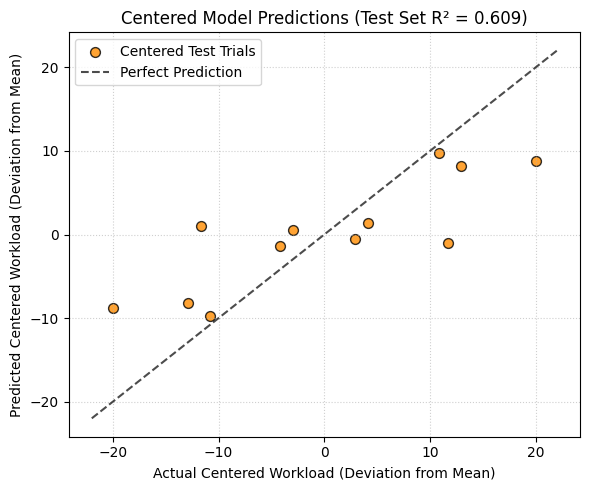

In [16]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test_c, pred_test_c, color='darkorange', edgecolors='k', s=50, alpha=0.8, label='Centered Test Trials')

# Reference diagonal line
lims = [min(y_test_c.min(), pred_test_c.min()) - 2, max(y_test_c.max(), pred_test_c.max()) + 2]
plt.plot(lims, lims, 'k--', alpha=0.7, label='Perfect Prediction')

plt.xlabel('Actual Centered Workload (Deviation from Mean)')
plt.ylabel('Predicted Centered Workload (Deviation from Mean)')
plt.title(f'Centered Model Predictions (Test Set R² = {centered_r2:.3f})')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Side-by-Side Model Comparison

Let's organize the metrics from our previous attempts and compare them directly to our new centered regression model. This will clearly highlight how centering resolved the negative $R^2$ and reduced the prediction error.

,Approach,Test MAE,Test RMSE,Test R²
0,Original MLR (Absolute),18.625,21.442,-0.384
1,Ridge Regression (Absolute),18.315,21.706,-0.418
2,Within-Subject Centered MLR (Relative),5.999,7.426,0.609


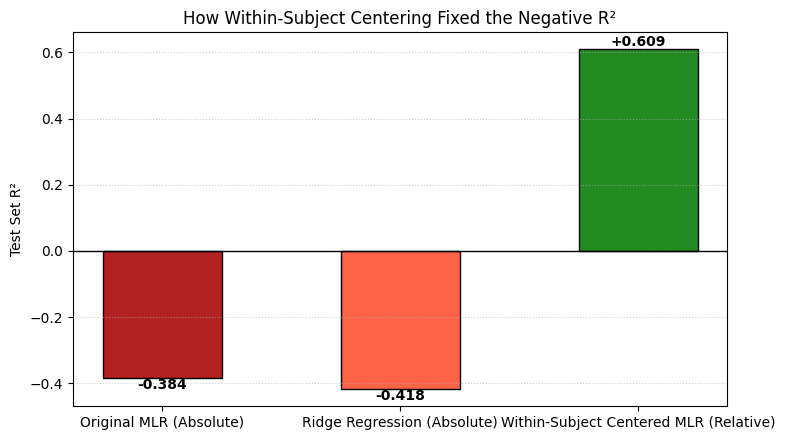

In [17]:
# Compile the results from all approaches
comparison_data = [
    {"Approach": "Original MLR (Absolute)", "Test MAE": m.loc['MLR - test', 'MAE'], "Test RMSE": m.loc['MLR - test', 'RMSE'], "Test R²": m.loc['MLR - test', 'R2']},
    {"Approach": "Ridge Regression (Absolute)", "Test MAE": ridge_mae, "Test RMSE": ridge_rmse, "Test R²": ridge_r2},
    {"Approach": "Within-Subject Centered MLR (Relative)", "Test MAE": centered_mae, "Test RMSE": centered_rmse, "Test R²": centered_r2}
]

df_compare = pd.DataFrame(comparison_data).round(3)
display(df_compare)

# Plot a comparison of the Test R² metrics
plt.figure(figsize=(8, 4.5))
colors = ['firebrick', 'tomato', 'forestgreen']
bars = plt.bar(df_compare['Approach'], df_compare['Test R²'], color=colors, edgecolor='black', width=0.5)
plt.axhline(0, color='black', linewidth=1, linestyle='-')
plt.ylabel('Test Set R²')
plt.title('How Within-Subject Centering Fixed the Negative R²')
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Annotate bar values
for bar in bars:
    yval = bar.get_height()
    va_dir = 'bottom' if yval >= 0 else 'top'
    plt.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:+.3f}", ha='center', va=va_dir, fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()